# 2층 신경망 역전파: 연쇄 법칙 유도와 NumPy 검증

**목표**

- 입력 2 → 은닉 2 → 출력 1, Sigmoid, BCE 신경망의 순전파와 모든 기울기를 **연쇄 법칙으로 손계산**한다.
- 손계산 값과 NumPy 구현을 **소수점 4자리까지** 비교한다.
- 역전파 기울기를 **수치 미분(중심차분)** 과 대조해 구현이 맞는지 독립적으로 검증한다.

**읽는 순서**: 1 문제 설정 → 2 순전파 손계산 → 3 역전파 유도 → 4 NumPy 검증 → 5 수치 미분 검증 → 6 목표값이 0인 경우 → 7 시각화 → 8 실제로 학습되는지 확인

구현은 [`src/backprop.py`](../src/backprop.py)에 있고, 이 노트북은 그 함수를 호출해 손계산과 비교한다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from src import backprop as bp
from src.plotting import AQUA, BLUE, INK_SECONDARY, ORANGE, save_figure, setup_style

np.random.seed(42)
setup_style()
np.set_printoptions(precision=6, suppress=True)

## 1. 문제 설정

### 구조

$$
z_1 = W_1 x + b_1 \;\in\mathbb{R}^2,\qquad
a_1 = \sigma(z_1)\;\in\mathbb{R}^2,\qquad
z_2 = W_2 \cdot a_1 + b_2 \;\in\mathbb{R},\qquad
\hat y = \sigma(z_2)\;\in\mathbb{R}
$$

$$
L = -\big[\,y\ln\hat y + (1-y)\ln(1-\hat y)\,\big],\qquad \sigma(z)=\frac{1}{1+e^{-z}}
$$

### 고정값

$$
x=\begin{pmatrix}1\\0\end{pmatrix},\quad
W_1=\begin{pmatrix}0.1&0.2\\0.3&0.4\end{pmatrix},\quad
b_1=\begin{pmatrix}0\\0\end{pmatrix},\quad
W_2=\begin{pmatrix}0.5&0.6\end{pmatrix},\quad
b_2=0
$$

### 표기 약속 (손계산 전에 먼저 못박아 둔다)

- **`W @ x` 관례**: $W_1[i,j]$는 입력 $j$에서 은닉 뉴런 $i$로 가는 가중치다. 그래서 $z_1[i]=\sum_j W_1[i,j]\,x[j]+b_1[i]$이고 shape은 $W_1:(2,2)$, $W_2:(2,)$다. 같은 값을 $x W_1$ 방식으로 읽으면 $z_1=(0.1,\,0.2)$가 되어 결과가 달라지므로 약속을 분명히 해야 한다.
- **목표값 $y$**: 미션 원문에는 $y$가 정해져 있지 않다. 이 노트북은 **$y=1$** 을 기준으로 계산한다. $\hat y\approx0.65$를 1쪽으로 끌어올리는 방향이라 기울기 부호를 해석하기 쉽기 때문이다. $y=0$ 결과는 6장에 함께 적었다.
- 모든 중간 계산은 계산기로 하듯 **소수점 6자리에서 반올림**하고, 최종 비교만 4자리로 한다.

## 2. 순전파 손계산

### 2-1. 은닉층 선형 결합 $z_1 = W_1x+b_1$

$$
z_1[0]=0.1\cdot1+0.2\cdot0+0=\mathbf{0.1},\qquad
z_1[1]=0.3\cdot1+0.4\cdot0+0=\mathbf{0.3}
$$

$x_2=0$이라 $W_1$의 두 번째 열은 아무 영향도 주지 못한다. 이 사실은 역전파에서 다시 나온다.

### 2-2. Sigmoid $a_1=\sigma(z_1)$

$$
a_1[0]=\frac{1}{1+e^{-0.1}}=\frac{1}{1+0.904837}=\frac{1}{1.904837}=\mathbf{0.524979}
$$

$$
a_1[1]=\frac{1}{1+e^{-0.3}}=\frac{1}{1+0.740818}=\frac{1}{1.740818}=\mathbf{0.574443}
$$

### 2-3. 출력층 선형 결합 $z_2=W_2\cdot a_1+b_2$

$$
z_2=0.5\cdot0.524979+0.6\cdot0.574443+0=0.262489+0.344666=\mathbf{0.607155}
$$

### 2-4. 예측값 $\hat y=\sigma(z_2)$

$$
\hat y=\frac{1}{1+e^{-0.607155}}=\frac{1}{1+0.544899}=\mathbf{0.647292}
$$

### 2-5. 손실 (BCE, $y=1$)

$$
L=-\ln\hat y=-\ln(0.647292)=\mathbf{0.434958}
$$

In [2]:
x, params = bp.fixed_inputs()
cache = bp.forward(x, params)
loss = bp.bce_loss(float(cache["y_pred"]), 1.0)

print("순전파 (NumPy)")
for name in ("z1", "a1", "z2", "y_pred"):
    print(f"  {name:<7} shape={str(np.shape(cache[name])):<6} {np.round(cache[name], 4)}")
print(f"  L       (y=1)           {loss:.4f}")

순전파 (NumPy)
  z1      shape=(2,)   [0.1 0.3]
  a1      shape=(2,)   [0.525  0.5744]
  z2      shape=()     0.6072
  y_pred  shape=()     0.6473
  L       (y=1)           0.4350


## 3. 역전파 유도

### 3-0. 연쇄 법칙의 구조

계산 그래프는 한 줄이다.

$$
(W_1,b_1)\;\to\; z_1\;\to\; a_1\;\to\; z_2\;\to\; \hat y\;\to\; L
$$

$L$이 $W_1$에 의존하는 경로가 이 한 줄뿐이므로, 각 화살표의 국소 미분을 **출력쪽부터 곱해** 가면 된다.

$$
\frac{\partial L}{\partial W_1}=
\underbrace{\frac{\partial L}{\partial \hat y}\frac{\partial \hat y}{\partial z_2}}_{\partial L/\partial z_2}
\;\underbrace{\frac{\partial z_2}{\partial a_1}}_{W_2}
\;\underbrace{\frac{\partial a_1}{\partial z_1}}_{\sigma'(z_1)}
\;\underbrace{\frac{\partial z_1}{\partial W_1}}_{x^\top}
$$

앞쪽에서 이미 구한 $\partial L/\partial z_2$를 재사용해 뒤쪽으로 전달하는 것이 역전파(backpropagation)다.

### 3-1. 필요한 국소 미분 두 가지

**Sigmoid의 미분**

$$
\sigma'(z)=\frac{e^{-z}}{(1+e^{-z})^2}=\frac{1}{1+e^{-z}}\cdot\frac{e^{-z}}{1+e^{-z}}=\sigma(z)\big(1-\sigma(z)\big)
$$

**BCE의 미분**

$$
\frac{\partial L}{\partial\hat y}=-\frac{y}{\hat y}+\frac{1-y}{1-\hat y}=\frac{\hat y-y}{\hat y(1-\hat y)}
$$

### 3-2. 출력층

$\partial\hat y/\partial z_2=\sigma'(z_2)=\hat y(1-\hat y)$이므로 분모가 **약분**된다.

$$
\frac{\partial L}{\partial z_2}=\frac{\hat y-y}{\hat y(1-\hat y)}\cdot\hat y(1-\hat y)=\hat y-y
=0.647292-1=\mathbf{-0.352708}
$$

$z_2=W_2\cdot a_1+b_2$이므로 $\partial z_2/\partial W_2=a_1,\ \partial z_2/\partial b_2=1$이다.

$$
\frac{\partial L}{\partial W_2}=\frac{\partial L}{\partial z_2}\,a_1
=\big(-0.352708\cdot0.524979,\ -0.352708\cdot0.574443\big)
=\mathbf{(-0.185164,\ -0.202611)}
$$

$$
\frac{\partial L}{\partial b_2}=\frac{\partial L}{\partial z_2}=\mathbf{-0.352708}
$$

### 3-3. 은닉층으로 전달

$\partial z_2/\partial a_1=W_2$이므로

$$
\frac{\partial L}{\partial a_1}=W_2\,\frac{\partial L}{\partial z_2}
=\big(0.5\cdot(-0.352708),\ 0.6\cdot(-0.352708)\big)
=\mathbf{(-0.176354,\ -0.211625)}
$$

Sigmoid 지나기 전으로: $\partial a_1/\partial z_1=\sigma'(z_1)=a_1\odot(1-a_1)$이다 ($\odot$는 원소별 곱).

$$
\sigma'(z_1)=\big(0.524979\cdot0.475021,\ 0.574443\cdot0.425557\big)=(0.249376,\ 0.244458)
$$

$$
\frac{\partial L}{\partial z_1}=\frac{\partial L}{\partial a_1}\odot\sigma'(z_1)
=\big(-0.176354\cdot0.249376,\ -0.211625\cdot0.244458\big)
=\mathbf{(-0.043978,\ -0.051733)}
$$

### 3-4. 은닉층 파라미터

$z_1[i]=\sum_jW_1[i,j]x[j]+b_1[i]$이므로 $\partial z_1[i]/\partial W_1[i,j]=x[j]$, $\partial z_1[i]/\partial b_1[i]=1$이다.

$$
\frac{\partial L}{\partial W_1}=\frac{\partial L}{\partial z_1}\,x^\top
=\begin{pmatrix}-0.043978\\-0.051733\end{pmatrix}\begin{pmatrix}1&0\end{pmatrix}
=\mathbf{\begin{pmatrix}-0.043978&0\\-0.051733&0\end{pmatrix}}
$$

$$
\frac{\partial L}{\partial b_1}=\frac{\partial L}{\partial z_1}=\mathbf{(-0.043978,\ -0.051733)}
$$

**해석**: 두 번째 열의 기울기가 0인 이유는 $x_2=0$이라 $W_1[:,1]$이 이번 샘플의 손실에 전혀 관여하지 않았기 때문이다. 기울기는 "위에서 내려온 오차 $\delta$"에 "그 가중치가 곱해진 입력"을 곱한 값이다.

### 3-5. shape 점검

기울기는 항상 **미분 대상과 같은 shape**이다.

| 기울기 | shape | 만드는 식 |
|---|---|---|
| $\partial L/\partial z_2$ | `()` 스칼라 | $\hat y-y$ |
| $\partial L/\partial W_2$ | `(2,)` | `dz2 * a1` |
| $\partial L/\partial b_2$ | `()` | `dz2` |
| $\partial L/\partial a_1$ | `(2,)` | `W2 * dz2` |
| $\partial L/\partial z_1$ | `(2,)` | `da1 * a1 * (1 - a1)` |
| $\partial L/\partial W_1$ | `(2, 2)` | `np.outer(dz1, x)` |
| $\partial L/\partial b_1$ | `(2,)` | `dz1` |

## 4. NumPy 검증: 손계산 vs 구현 (소수점 4자리)

아래 `hand`는 2장과 3장에서 손으로 구한 값을 **소수점 4자리로 옮겨 적은 것**이고, NumPy 값은 `src/backprop.py`의 `forward`와 `backward`가 계산한다. 4자리로 반올림한 두 값이 모두 같아야 통과다.

In [3]:
hand = {
    "z1": [0.1, 0.3],
    "a1": [0.525, 0.5744],
    "z2": 0.6072,
    "y_pred": 0.6473,
    "L": 0.435,
    "dz2": -0.3527,
    "dW2": [-0.1852, -0.2026],
    "db2": -0.3527,
    "da1": [-0.1764, -0.2116],
    "dz1": [-0.044, -0.0517],
    "dW1": [[-0.044, 0.0], [-0.0517, 0.0]],
    "db1": [-0.044, -0.0517],
}

grads = bp.backward(cache, params, 1.0)
numpy_values = {**cache, **grads, "L": loss}

print(f"{'이름':<8}{'shape':<9}{'손계산':<36}{'NumPy':<36}결과")
all_match = True
for name, expected in hand.items():
    actual = np.round(numpy_values[name], 4) + 0.0
    ok = bool(np.allclose(actual, expected, atol=1e-9))
    all_match &= ok
    print(f"{name:<8}{str(np.shape(actual)):<9}{str(expected):<36}{str(actual.tolist()):<36}{'일치' if ok else '불일치'}")

assert all_match, "손계산과 NumPy가 4자리에서 일치하지 않는 항목이 있습니다"
print("\n모든 항목이 소수점 4자리까지 일치합니다.")

이름      shape    손계산                                 NumPy                               결과
z1      (2,)     [0.1, 0.3]                          [0.1, 0.3]                          일치
a1      (2,)     [0.525, 0.5744]                     [0.525, 0.5744]                     일치
z2      ()       0.6072                              0.6072                              일치
y_pred  ()       0.6473                              0.6473                              일치
L       ()       0.435                               0.435                               일치
dz2     ()       -0.3527                             -0.3527                             일치
dW2     (2,)     [-0.1852, -0.2026]                  [-0.1852, -0.2026]                  일치
db2     ()       -0.3527                             -0.3527                             일치
da1     (2,)     [-0.1764, -0.2116]                  [-0.1764, -0.2116]                  일치
dz1     (2,)     [-0.044, -0.0517]                   [-0.044, -0.0517]          

In [4]:
print("shape 기록")
print("  순전파  :", bp.shapes(cache))
print("  기울기  :", bp.shapes(grads))
for name in ("W1", "b1", "W2", "b2"):
    assert grads["d" + name].shape == params[name].shape
print("\n파라미터 W1, b1, W2, b2의 기울기는 모두 파라미터와 같은 shape입니다.")

shape 기록
  순전파  : {'x': (2,), 'z1': (2,), 'a1': (2,), 'z2': (), 'y_pred': ()}
  기울기  : {'dz2': (), 'dW2': (2,), 'db2': (), 'da1': (2,), 'dz1': (2,), 'dW1': (2, 2), 'db1': (2,), 'dx': (2,)}

파라미터 W1, b1, W2, b2의 기울기는 모두 파라미터와 같은 shape입니다.


## 5. 수치 미분으로 독립 검증

손계산과 구현이 같은 실수를 공유할 수도 있다. 그래서 유도와 무관하게 **정의 그대로** 기울기를 구해 대조한다. 각 파라미터 원소를 $\pm h$ 흔들어

$$
\frac{\partial L}{\partial\theta}\approx\frac{L(\theta+h)-L(\theta-h)}{2h},\qquad h=10^{-6}
$$

로 계산하고 역전파 값과의 **최대 절대 오차**를 본다.

In [5]:
numeric = bp.numerical_gradients(x, params, 1.0)
errors = bp.gradient_check(x, params, 1.0)

print(f"{'파라미터':<8}{'역전파':<44}{'수치 미분':<44}최대 오차")
for name in ("W1", "b1", "W2", "b2"):
    print(f"{name:<8}{str(np.round(grads['d' + name], 6).tolist()):<44}{str(np.round(numeric[name], 6).tolist()):<44}{errors[name]:.1e}")

assert max(errors.values()) < 1e-8
print("\n최대 오차가 1e-8보다 작으므로 역전파 구현이 정의와 일치합니다.")

파라미터    역전파                                         수치 미분                                       최대 오차
W1      [[-0.043979, -0.0], [-0.051734, -0.0]]      [[-0.043979, 0.0], [-0.051734, 0.0]]        1.0e-10
b1      [-0.043979, -0.051734]                      [-0.043979, -0.051734]                      1.0e-10
W2      [-0.185165, -0.202611]                      [-0.185165, -0.202611]                      8.6e-11
b2      -0.352708                                   -0.352708                                   1.3e-11

최대 오차가 1e-8보다 작으므로 역전파 구현이 정의와 일치합니다.


## 6. 목표값이 $y=0$인 경우 (참고)

미션이 목표값을 정하지 않았으므로 $y=0$도 함께 적는다. 순전파는 목표값과 무관하니 같고, 역전파는 $\partial L/\partial z_2=\hat y-y$의 부호부터 달라진다. $y=1$이면 모든 기울기가 음수(가중치를 키워야 함), $y=0$이면 양수(줄여야 함)다.

In [6]:
grads0 = bp.backward(cache, params, 0.0)
loss0 = bp.bce_loss(float(cache["y_pred"]), 0.0)
print(f"y=0:  L = {loss0:.4f}  (y=1일 때 {loss:.4f})")
for name in ("dz2", "dW2", "db2", "da1", "dz1", "dW1", "db1"):
    print(f"  {name:<4} y=1 {np.round(grads[name], 4).tolist()}   y=0 {np.round(grads0[name], 4).tolist()}")
print("\ny=0 수치 검증 최대 오차:", {k: f"{v:.1e}" for k, v in bp.gradient_check(x, params, 0.0).items()})

y=0:  L = 1.0421  (y=1일 때 0.4350)
  dz2  y=1 -0.3527   y=0 0.6473
  dW2  y=1 [-0.1852, -0.2026]   y=0 [0.3398, 0.3718]
  db2  y=1 -0.3527   y=0 0.6473
  da1  y=1 [-0.1764, -0.2116]   y=0 [0.3236, 0.3884]
  dz1  y=1 [-0.044, -0.0517]   y=0 [0.0807, 0.0949]
  dW1  y=1 [[-0.044, -0.0], [-0.0517, -0.0]]   y=0 [[0.0807, 0.0], [0.0949, 0.0]]
  db1  y=1 [-0.044, -0.0517]   y=0 [0.0807, 0.0949]

y=0 수치 검증 최대 오차: {'W1': '1.3e-10', 'b1': '1.3e-10', 'W2': '1.2e-10', 'b2': '1.6e-11'}


## 7. 시각화: 값이 흐르는 방향과 기울기가 돌아오는 방향

왼쪽은 순전파 값(노드)과 가중치(간선), 오른쪽은 같은 간선 위에 **기울기** $\partial L/\partial W$를 적었다. 오른쪽 위쪽 간선이 모두 음수인 것은 $y=1$이라 가중치를 키우는 쪽으로 학습해야 한다는 뜻이다.

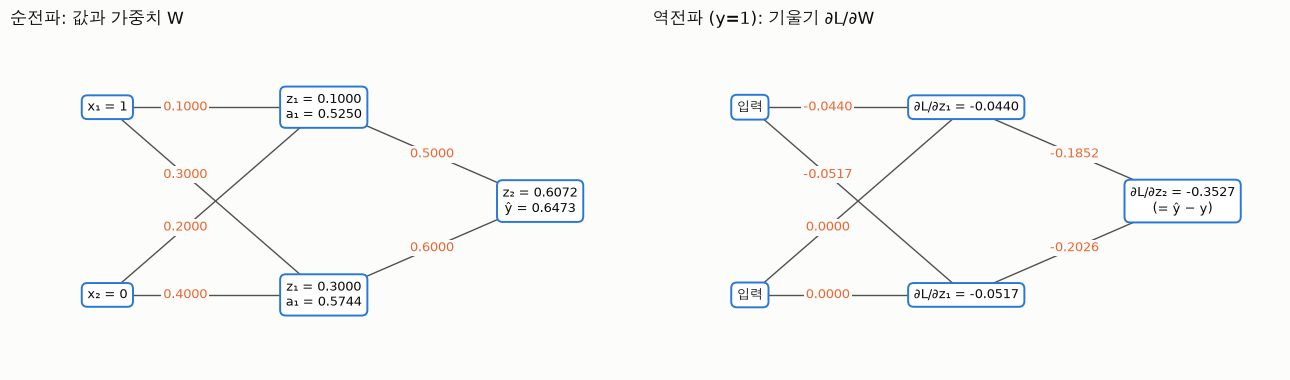

In [7]:
def draw_network(ax, nodes, edges, title):
    pos = {"x1": (0, 1), "x2": (0, 0), "h1": (1, 1), "h2": (1, 0), "y": (2, 0.5)}
    links = [("x1", "h1"), ("x2", "h1"), ("x1", "h2"), ("x2", "h2"), ("h1", "y"), ("h2", "y")]
    for a, b in links:
        (xa, ya), (xb, yb) = pos[a], pos[b]
        ax.plot([xa, xb], [ya, yb], color=INK_SECONDARY, linewidth=1.0, zorder=1)
        t = 0.5 if b == "y" else 0.36
        ax.text(xa + (xb - xa) * t, ya + (yb - ya) * t, edges[(a, b)], fontsize=9, ha="center",
                va="center", color=ORANGE, bbox={"fc": "#fcfcfb", "ec": "none", "pad": 1.5}, zorder=2)
    for name, (px, py) in pos.items():
        ax.text(px, py, nodes[name], ha="center", va="center", fontsize=9, zorder=3,
                bbox={"boxstyle": "round,pad=0.45", "fc": "white", "ec": BLUE, "lw": 1.4})
    ax.set_xlim(-0.45, 2.45)
    ax.set_ylim(-0.4, 1.4)
    ax.set_title(title, loc="left")
    ax.axis("off")


f = lambda v: f"{float(v):.4f}"
a1, z1 = cache["a1"], cache["z1"]
fwd_nodes = {
    "x1": f"x₁ = {x[0]:.0f}", "x2": f"x₂ = {x[1]:.0f}",
    "h1": f"z₁ = {f(z1[0])}\na₁ = {f(a1[0])}", "h2": f"z₁ = {f(z1[1])}\na₁ = {f(a1[1])}",
    "y": f"z₂ = {f(cache['z2'])}\nŷ = {f(cache['y_pred'])}",
}
W1, W2 = params["W1"], params["W2"]
fwd_edges = {("x1", "h1"): f(W1[0, 0]), ("x2", "h1"): f(W1[0, 1]), ("x1", "h2"): f(W1[1, 0]),
             ("x2", "h2"): f(W1[1, 1]), ("h1", "y"): f(W2[0]), ("h2", "y"): f(W2[1])}
dW1, dW2, dz1 = grads["dW1"], grads["dW2"], grads["dz1"]
bwd_nodes = {
    "x1": "입력", "x2": "입력",
    "h1": f"∂L/∂z₁ = {f(dz1[0])}", "h2": f"∂L/∂z₁ = {f(dz1[1])}",
    "y": f"∂L/∂z₂ = {f(grads['dz2'])}\n(= ŷ − y)",
}
bwd_edges = {("x1", "h1"): f(dW1[0, 0]), ("x2", "h1"): f(dW1[0, 1] + 0.0), ("x1", "h2"): f(dW1[1, 0]),
             ("x2", "h2"): f(dW1[1, 1] + 0.0), ("h1", "y"): f(dW2[0]), ("h2", "y"): f(dW2[1])}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
draw_network(axes[0], fwd_nodes, fwd_edges, "순전파: 값과 가중치 W")
draw_network(axes[1], bwd_nodes, bwd_edges, "역전파 (y=1): 기울기 ∂L/∂W")
fig.tight_layout()
save_figure(fig, "backprop_network.png")
plt.show()

## 8. 기울기가 맞다면 실제로 학습되어야 한다

계산한 기울기로 경사하강법($\theta\leftarrow\theta-\eta\,\partial L/\partial\theta$, $\eta=0.5$)을 200번 돌려 손실이 줄고 $\hat y$가 목표값 1에 다가가는지 본다. 기울기 부호가 틀렸다면 손실이 오히려 커졌을 것이다.

손실  0.4350 → 0.0040   예측 ŷ  0.6473 → 0.9960


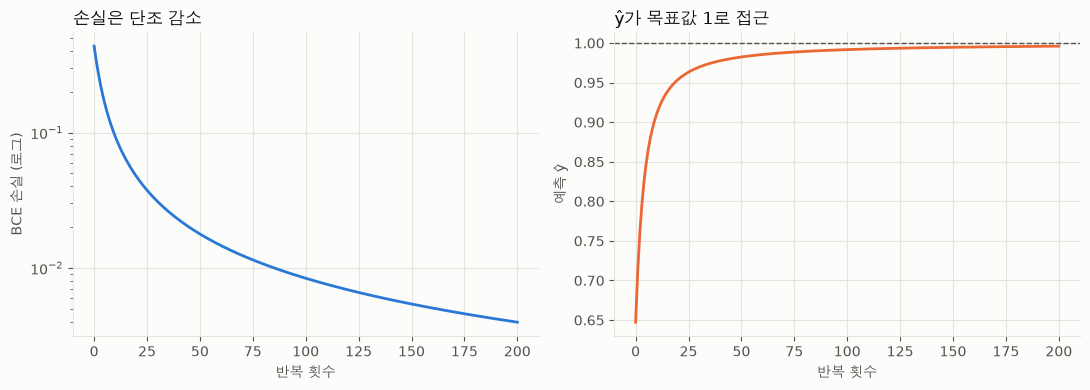

In [8]:
lr, steps = 0.5, 200
trained = {name: np.array(value, dtype=float) for name, value in params.items()}
losses, preds = [], []
for _ in range(steps + 1):
    state = bp.forward(x, trained)
    losses.append(bp.bce_loss(float(state["y_pred"]), 1.0))
    preds.append(float(state["y_pred"]))
    g = bp.backward(state, trained, 1.0)
    for name in ("W1", "b1", "W2", "b2"):
        trained[name] = np.asarray(trained[name] - lr * g["d" + name])

print(f"손실  {losses[0]:.4f} → {losses[-1]:.4f}   예측 ŷ  {preds[0]:.4f} → {preds[-1]:.4f}")
assert losses[-1] < losses[0] and all(b <= a + 1e-12 for a, b in zip(losses, losses[1:]))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.semilogy(losses, color=BLUE)
left.set_xlabel("반복 횟수")
left.set_ylabel("BCE 손실 (로그)")
left.set_title("손실은 단조 감소", loc="left")
right.plot(preds, color=ORANGE)
right.axhline(1.0, color=INK_SECONDARY, linestyle="--", linewidth=1.0)
right.set_xlabel("반복 횟수")
right.set_ylabel("예측 ŷ")
right.set_title("ŷ가 목표값 1로 접근", loc="left")
fig.tight_layout()
save_figure(fig, "backprop_training.png")
plt.show()

## 정리

- 연쇄 법칙은 **국소 미분을 출력쪽부터 곱해 내려오는 것**이다. 출력층에서 Sigmoid와 BCE가 만나면 $\partial L/\partial z_2=\hat y-y$로 깔끔해진다.
- 가중치의 기울기는 (위에서 내려온 오차) × (그 가중치가 곱해진 입력)이다. 그래서 입력이 0인 열의 기울기는 0이다.
- 기울기 shape은 파라미터 shape과 같다. shape이 맞지 않으면 유도 어딘가가 틀린 것이다.
- 손계산과 NumPy는 소수점 4자리까지 일치했고, 수치 미분과의 오차도 $10^{-8}$ 미만이며, 그 기울기로 실제 학습이 된다.

**한계**: 샘플 1개, 층 2개짜리 계산이다. 배치(N개 샘플)에서는 $\partial L/\partial W$에 샘플 평균이 들어가고 shape에 배치 축이 추가되며, 층이 깊어지면 Sigmoid의 $\sigma'\le0.25$가 반복해서 곱해져 기울기가 작아지는 문제(vanishing gradient)가 생긴다.